# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [33]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
# YOUR CODE HERE
raise NotImplementedError()
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

Matplotlib: 3.11.2
Seaborn: 0.13.2


NotImplementedError: 

In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [34]:
# Initialize S, theta and bias
S =  np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) 
theta = ([0.3],[0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + 0.5

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5) 
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails 
predicted_spam = probabilities >= 0.5

# YOUR CODE HERE
raise NotImplementedError()

NotImplementedError: 

In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities) 
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [35]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [36]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"
indexes = rng.choice(n, 12, replace=False)

log.loc[indexes, "failed_attempts"] = rng.integers(5, 11, 12)
# Write your code here

In [6]:
# Autograded cell (Failed attempts)
# Skip it

In [37]:
# Insert 10 missing values randomly
idx = rng.choice(log.size, 10, replace=False)

log.values.flat[idx] = np.nan
# Write your code here

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [38]:
# Write your code here
result = log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)]

print(len(result))
# ru_log_at_least_five_attempts = ...

1


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [39]:
# Write your code here
result = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False)

print(result.index[0])
# user_max_failed_attempts = 

karim


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [40]:
# Write your code here
# log['long_session'] = ...
log["long_session"] = np.where(log["duration_min"] > 30, 1, 0)

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

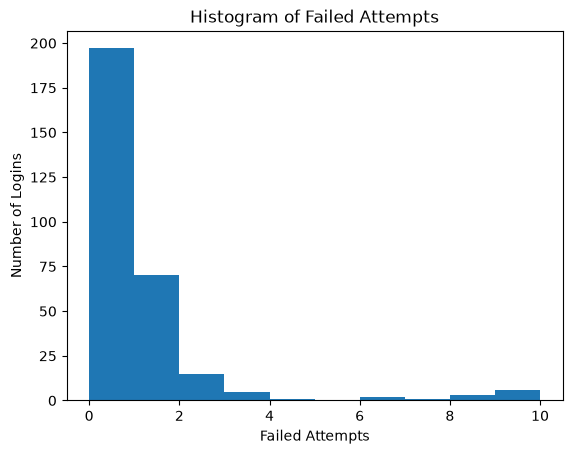

In [11]:
# Draw the histogram of failed_attempts.
# Write your code he
plt.hist(log["failed_attempts"])
plt.xlabel("Failed Attempts")
plt.ylabel("Number of Logins")
plt.title("Histogram of Failed Attempts")

plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [12]:
# Write your code here
# answer_q2 = ...
"The distribution is highly skewed with zero-inflation and rare extreme bursts."

'The distribution is highly skewed with zero-inflation and rare extreme bursts.'

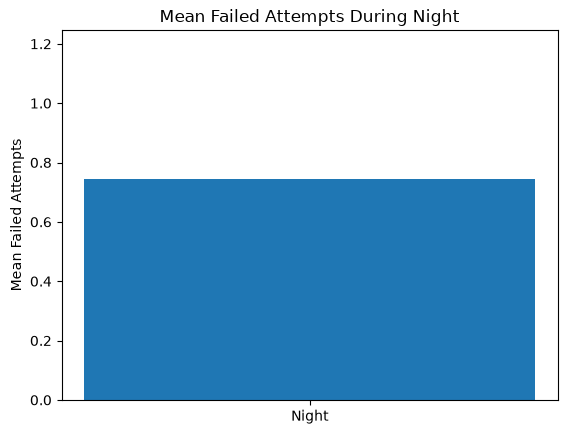

In [32]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
night = log[(log["hour"] >= 22) | (log["hour"] < 6)]
mean_night = night["failed_attempts"].mean()
plt.bar(["Night"], [mean_night], width=0.5)
plt.ylim(0, max(1, mean_night + 0.5))
plt.ylabel("Mean Failed Attempts")
plt.title("Mean Failed Attempts During Night")
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
"It selects all rows from the third column of array X, returning 300 values."

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [18]:
# Write your code here
log.isnull().sum()

user               0
hour               0
failed_attempts    0
country            0
duration_min       0
long_session       0
dtype: int64

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

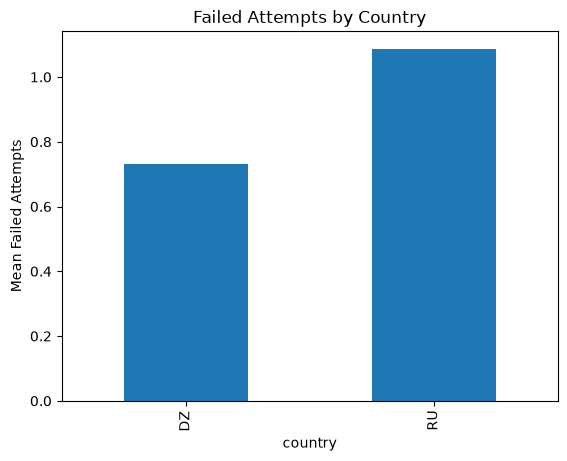

In [20]:
# Write your code here
log[log["country"].isin(["RU", "DZ"])].groupby("country")["failed_attempts"].mean().plot(kind="bar")

plt.ylabel("Mean Failed Attempts")
plt.title("Failed Attempts by Country")
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
"We scale features to make sure all variables have similar importance, so features with larger values dont unfairly influence the model."

Commit the logins_clean.csv.(0.5 point)

In [41]:
# save the cleaned table in login_clean.csv
# Write your code here
log.to_csv("login_clean.csv", index=False)

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [42]:
# Write your code here
df = pd.read_csv("login_clean.csv")
df["night"] = np.where(
    (df["hour"] >= 22) | (df["hour"] < 6), 1, 0
)
cols = ["hour", "failed_attempts", "duration_min", "night"]
NewNp = df[cols].to_numpy()
NewNp = (NewNp - NewNp.mean(axis=0)) / NewNp.std(axis=0)
print(NewNp.shape)

(300, 4)


In [ ]:
import numpy as np
import pandas as pd
